# Stock price forecasting using LOB

### Import modules

In [1]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from plotly.subplots import make_subplots
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score, mean_absolute_percentage_error, root_mean_squared_error

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_regression as Models
import utils
import dataset as Dataset

In [84]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda:0


In [96]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,1.326816,-0.316930,1.325949,-0.007630,1.326211,-0.449060,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383
99996,1.326816,-0.316930,1.325949,0.115155,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99997,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99998,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383


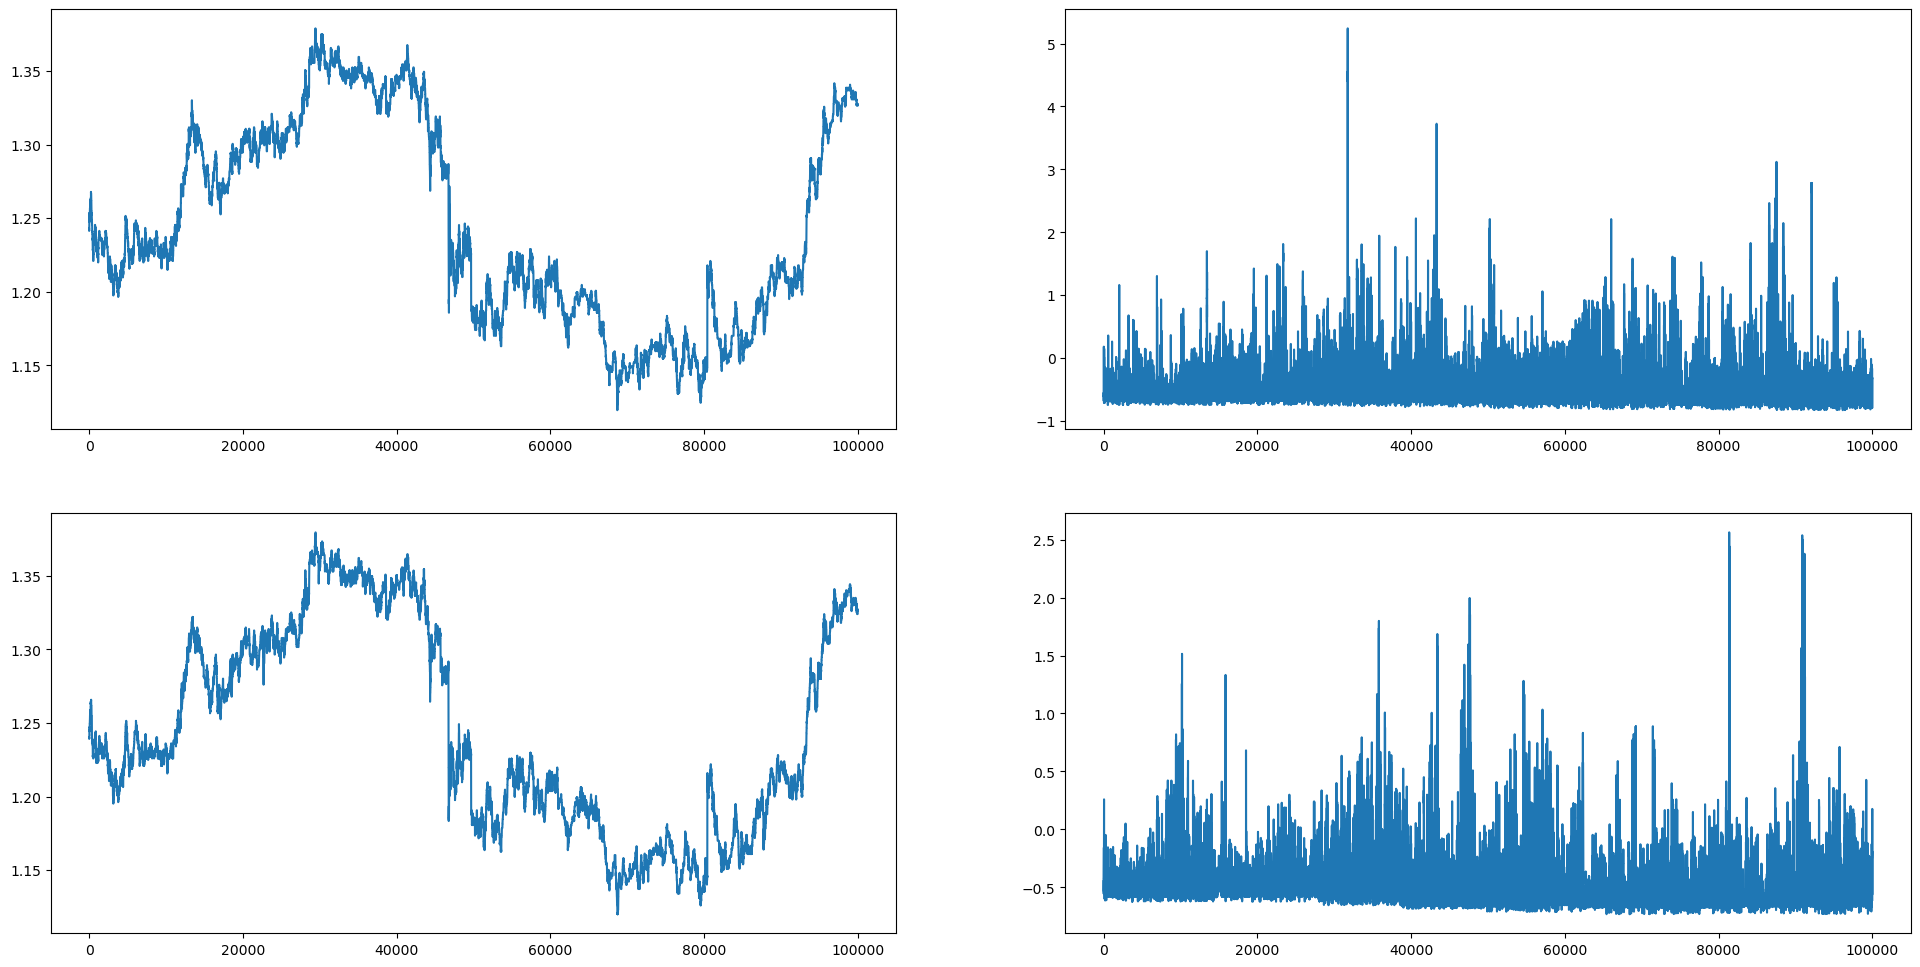

In [97]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

## Single Horizon Regression:

Create the effective time-series dataset, and the batch-iterators to process tensors using the sliding window procedure

In [98]:
target_col = 'mid_price'
target_cols = []
shifts = [ 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_50
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302,1.248455
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.248455
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.247943
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.248455
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.248455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99945,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,1.321342,-0.467108,1.316635,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.326383
99946,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,1.321342,-0.467108,1.316635,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.326383
99947,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,1.321342,-0.467108,1.316635,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.326383
99948,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,1.321342,-0.467108,1.319645,-0.206374,1.322448,-0.444968,1.319378,-0.492045,1.325382,1.326383


In [99]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
#scaler = preprocessing.StandardScaler()
#scaler.fit(dataset_train)

#dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
#dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
#dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

means = dataset_train.mean(axis=0)
stds = dataset_train.std(axis=0)

means[-len(target_cols):] = means[target_cols]
stds[-len(target_cols):] = stds[target_cols]

dataset_train = ( dataset_train - means ) / stds
dataset_val = ( dataset_val - means ) / stds
dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_50
0,-0.308219,-0.526534,-0.342036,0.003483,-0.316814,-0.457742,-0.333217,0.032109,-0.325050,-0.477706,...,-0.341037,-0.611966,-0.295169,-0.654436,-0.371768,-0.784013,-0.290149,0.809870,-0.325283,-0.211284
1,-0.324367,-0.715414,-0.342036,-0.468958,-0.332951,-0.457742,-0.333217,-0.403441,-0.341190,-0.477706,...,-0.405592,-0.584624,-0.279181,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.211284
2,-0.324367,-0.715414,-0.342036,-0.080118,-0.332951,-0.457742,-0.333217,-0.403441,-0.341190,-0.477706,...,-0.405592,-0.584624,-0.279181,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.219325
3,-0.324367,-0.715414,-0.342036,-0.406744,-0.332951,-0.457742,-0.333217,0.032109,-0.341190,-0.477706,...,-0.405592,-0.584624,-0.279181,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.211284
4,-0.324367,-0.715414,-0.342036,-0.406744,-0.332951,-0.457742,-0.333217,0.032109,-0.341190,-0.477706,...,-0.405592,-0.584624,-0.279181,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.211284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69960,-1.919547,0.259077,-1.892896,-0.476571,-1.927403,-0.654619,-1.883781,0.643151,-1.935645,-0.647523,...,-1.986468,-0.873577,-1.912670,-1.097132,-1.994690,1.890540,-1.901760,-0.920434,-1.906589,-1.871570
69961,-1.919547,0.665861,-1.908623,0.855497,-1.927403,-0.654619,-1.899523,-0.321598,-1.935645,-0.647523,...,-1.954777,2.003863,-1.944085,-1.005132,-1.962980,-0.679220,-1.948815,-1.007881,-1.914492,-1.871570
69962,-1.919547,-0.279912,-1.908623,0.855497,-1.927403,-0.654619,-1.899523,-0.321598,-1.935645,-0.647523,...,-1.954777,2.003863,-1.912670,-1.097132,-1.962980,-0.679220,-1.901760,-0.920434,-1.914492,-1.871570
69963,-1.919547,-0.686696,-1.908623,0.855497,-1.927403,-0.654619,-1.899523,-0.321598,-1.935645,-0.647523,...,-1.954777,2.003863,-1.912670,-1.097132,-1.962980,-0.679220,-1.901760,-0.920434,-1.914492,-1.871570


In [100]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 128,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 69766 samples
Test dataset: 14794 samples


In [101]:
true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(features[:, -1, 40].numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print("dummy regressor: last value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))


true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(np.mean(features[:, :, 40].numpy(), axis=1))

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print()
print("dummy regressor: mean value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))

dummy regressor: last value

50        sMAPE:  13.067761063575745     RMSE:  0.06531842

dummy regressor: mean value

50        sMAPE:  17.00170934200287     RMSE:  0.094640076


### Baisc LSTM

In [102]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [103]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTM1(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name + '-SH-' + f'{shifts[0]}',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved


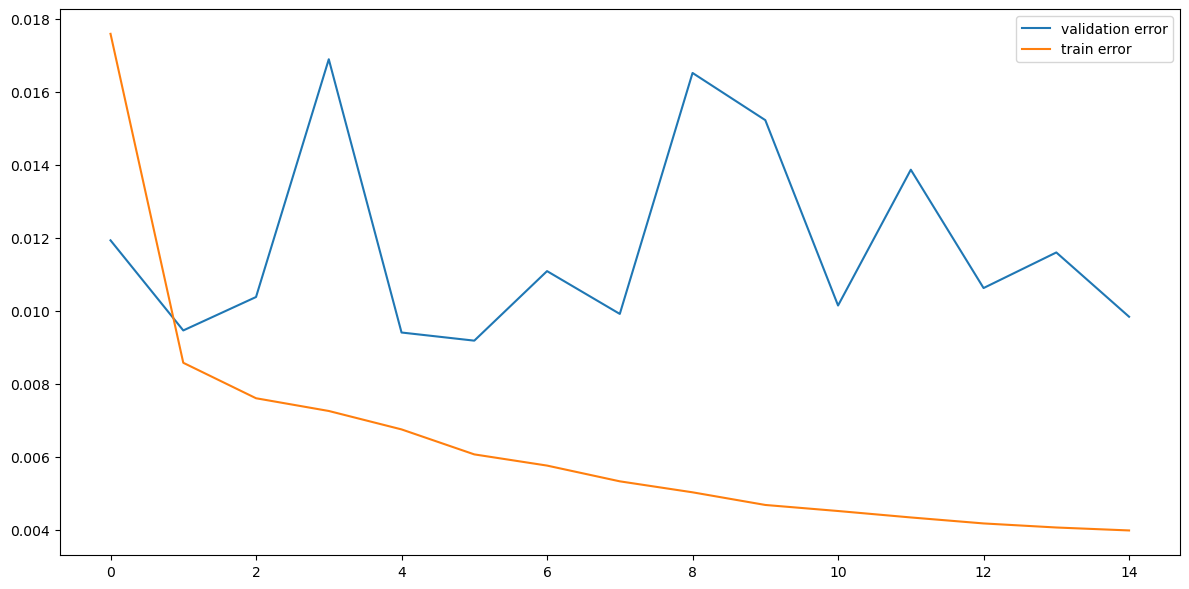

In [104]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-SH-{shifts[0]}-FI-reg-LOSS.pdf')
plt.show()

In [105]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/LSTM1-SH-{shifts[0]}-FI-best_model.pt', weights_only=False)

true_50 = []
pred_50 = []

torch.cuda.empty_cache()
# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true_50.append(labels.cpu().numpy())
        pred_50.append(outputs.cpu().numpy())

true_50 = np.concatenate(true_50).reshape(-1, y_train.shape[1])
pred_50 = np.concatenate(pred_50).reshape(-1, y_train.shape[1])
print(true_50.shape)
# Plot each dimension separately
fig = go.Figure()
fig.add_scatter(y=true_50[:,0], mode='lines', name= "Actual asset price", line_color = "navy")
fig.add_scatter(y=pred_50[:,0], mode='lines', name= "Predicted asset price", line_color = "green")
fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price")
fig.write_html(f'./figures/{best_model.name}-SH-{shifts[0]}-FI-reg-pryce.html')
fig.show()

(14794, 1)


In [ ]:
#np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
#torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

In [106]:
for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true_50[:, i], pred_50[:, i]))
    print(r2_score(true_50[:, i], pred_50[:, i]))
    print(root_mean_squared_error(true_50[:, i], pred_50[:, i]))
    print()

16.62164479494095
0.9880431624524058
0.101927586



The simple LSTM model performs well, beating both the dummy regressors.

In [107]:
# final html plot for single horizon regression:
fig = make_subplots(rows=4, cols=1)
fig.add_scatter(y=true_10[:,0], mode='lines', name= "Actual asset price", line_color = "navy", row=1, col=1)
fig.add_scatter(y=pred_10[:,0], mode='lines', name= "Predicted asset price", line_color = "green", row=1, col=1)
fig.add_scatter(y=true_20[:,0], mode='lines', name= "Actual asset price", line_color = "navy", row=2, col=1)
fig.add_scatter(y=pred_20[:,0], mode='lines', name= "Predicted asset price", line_color = "green", row=2, col=1)
fig.add_scatter(y=true_30[:,0], mode='lines', name= "Actual asset price", line_color = "navy", row=3, col=1)
fig.add_scatter(y=pred_30[:,0], mode='lines', name= "Predicted asset price", line_color = "green", row=3, col=1)
fig.add_scatter(y=true_50[:,0], mode='lines', name= "Actual asset price", line_color = "navy", row=4, col=1)
fig.add_scatter(y=pred_50[:,0], mode='lines', name= "Predicted asset price", line_color = "green", row=4, col=1)
fig.update_layout(title = f"Single-Horizon: [10, 20, 30, 50]", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-SH-all-FI-reg-pryce.html')
fig.show()